# BoxMOT — DIPSER Detection and Tracking Validation

Validate BoxMOT's detector and tracker components against a DIPSER camera sequence.

The notebook reads timestamp-named PNGs from one selected camera ZIP archive, runs person detection, performs multi-object tracking, maps track IDs to manually annotated subject IDs, and visualizes the outputs.

## Prerequisites

- BoxMOT and its YOLO detector dependencies must be installed in the active environment.
- The notebook uses CUDA when available.

## 1. Imports and environment

In [269]:
from pathlib import Path, PurePosixPath
from zipfile import ZipFile
from tempfile import TemporaryDirectory
import json
import re
import cv2
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from boxmot import create_tracker
from boxmot.detectors import create_detector
from boxmot.structures import Frame

In [270]:
dataset_dir = Path(r'E:\Coding\Projects\fyp\data\DIPSER\DIPSEER')
labels_dir = dataset_dir.parent / "abi_labels"

In [271]:
assert dataset_dir.is_dir(), dataset_dir
assert labels_dir.is_dir(), labels_dir

DEVICE = "cuda:0" if torch.cuda.is_available() else "cpu"

print("Dataset:", dataset_dir)
print("Device:", DEVICE)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Dataset: E:\Coding\Projects\fyp\data\DIPSER\DIPSEER
Device: cuda:0
PyTorch: 2.9.0+cu126
CUDA available: True
GPU: NVIDIA GeForce GTX 1080


## 2. Select a camera sequence

Select one experiment and camera. Only the selected camera's annotations are loaded; no cross-camera identity association is performed.

In [272]:
GROUP = "group_03"
EXPERIMENT = "experiment_01"
CAMERA = "context_cam_02"

experiment_dir = dataset_dir / GROUP / EXPERIMENT
zip_path = experiment_dir / f"{CAMERA}.zip"
labels_path = labels_dir / GROUP / f"{EXPERIMENT}.json"

assert zip_path.is_file(), f"Archive not found: {zip_path}"
assert labels_path.is_file(), f"Annotations not found: {labels_path}"

with labels_path.open("r", encoding="utf-8") as f:
    annotations = json.load(f)

assert CAMERA in annotations, f"No annotations for {CAMERA}"
subject_labels = annotations[CAMERA]
assert subject_labels, f"No subject annotations for {CAMERA}"

print("Selected archive:", zip_path)
print("Selected annotations:", labels_path)
print("Annotated subjects:", len(subject_labels))

Selected archive: E:\Coding\Projects\fyp\data\DIPSER\DIPSEER\group_03\experiment_01\context_cam_02.zip
Selected annotations: E:\Coding\Projects\fyp\data\DIPSER\abi_labels\group_03\experiment_01.json
Annotated subjects: 13


## 3. Timestamp parsing and archive inspection

Frame ordering is derived from the timestamp encoded in each PNG filename, rather than ZIP member order.

In [273]:
def parse_timestamp(filename: str) -> float:
    stem = Path(filename).stem
    match = re.fullmatch(r"(\d{2})_(\d{2})_(\d{2})_(\d+)", stem)
    if not match:
        raise ValueError(f"Unexpected timestamp: {filename}")
    h, m, s, fraction = match.groups()
    return (
        int(h) * 3600 + int(m) * 60 + int(s)
        + int(fraction) / 10 ** len(fraction)
    )

with ZipFile(zip_path) as archive:
    image_members = [
        name for name in archive.namelist()
        if name.startswith("images/")
        and name.lower().endswith(".png")
    ]

image_members.sort(key=parse_timestamp)
assert image_members, "No PNG frames found in images/"
print("Frames:", len(image_members))
print("First frame:", image_members[0])
print("Last frame:", image_members[-1])

Frames: 1160
First frame: images/17_35_33_029516.png
Last frame: images/17_40_32_932767.png


## 4. Extract the selected ZIP archive

Only the selected camera archive is extracted. The temporary directory remains available during inference and is cleaned up at the end of the notebook.

In [274]:
temp_context = TemporaryDirectory(prefix="boxmot_dipser_")
temp_root = Path(temp_context.name)
extracted_frames = []

with ZipFile(zip_path) as archive:
    for member in image_members:
        relative = PurePosixPath(member)
        if relative.is_absolute() or ".." in relative.parts:
            raise ValueError(f"Unsafe ZIP path: {member}")
        destination = temp_root.joinpath(*relative.parts)
        destination.parent.mkdir(parents=True, exist_ok=True)
        destination.write_bytes(archive.read(member))
        extracted_frames.append(destination)

print("Extracted frames:", len(extracted_frames))

Extracted frames: 1160


## 5. Configure detector and tracker

YOLOv8n is used for person detection. Select either `strongsort` or `botsort` for tracking.

The tracker receives the actual frame, allowing a ReID-enabled implementation to generate missing appearance embeddings internally.

In [275]:
DETECTOR_NAME = "yolov10n"
TRACKER_NAME = "botsort"  # alternatively: "strongsort"

detector = create_detector(
    DETECTOR_NAME,
    device=DEVICE,
    options={
        "confidence": 0.30,
        "image_size": [1280, 720],
        "classes": [0],
    },
)

tracker = create_tracker(TRACKER_NAME, track_high_thresh=0.3, track_low_thresh=0.10, new_track_thresh=0.15)
print("Detector and tracker initialized.")

INFO     BotSort: det_thresh=0.3, max_age=30, max_obs=50, min_hits=3, iou_threshold=0.3, per_class=False,          
         class_ids=None, asso_func=iou, variable_dt=False

Detector and tracker initialized.


## 6. Inference configuration

`MAX_FRAMES` limits the sequence length for the initial validation. Every frame within that range is passed to the tracker in order.

In [276]:
MAX_FRAMES = 60
SHOW_FRAME_INDICES = {0, 1, 5, 10, 20, 30, 40, 50, 59}

detection_records = []
track_records = []
visualization_frames = []

frames_to_process = extracted_frames[:MAX_FRAMES]
first_timestamp = parse_timestamp(image_members[0])
tracker.reset()

print("Frames to process:", len(frames_to_process))

Frames to process: 60


## 7. Run detection and tracking

Each frame is converted to the canonical BoxMOT `Frame` structure. Detector output is passed directly to the tracker. Per-frame observations are collected inside the loop so that the complete tracklet history is retained.

In [277]:
for index, frame_path in enumerate(frames_to_process):
    bgr = cv2.imread(str(frame_path))
    if bgr is None:
        raise RuntimeError(f"Cannot read {frame_path}")

    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    timestamp = parse_timestamp(image_members[index])
    frame = Frame(
        image=torch.from_numpy(rgb).permute(2, 0, 1).contiguous(),
        sample_id=f"{CAMERA}:{index}",
        sequence_id=f"{GROUP}:{EXPERIMENT}:{CAMERA}",
        frame_index=index,
        timestamp_s=timestamp - first_timestamp,
        source_uri=f"{zip_path.name}!/{image_members[index]}",
    )

    detections = detector.predict([frame])[0]
    tracks = tracker.update(detections, frame)

    det_boxes = detections.geometry.values.numpy()
    det_scores = detections.scores.numpy()
    det_classes = detections.class_ids.numpy()

    track_boxes = tracks.geometry.values.numpy()
    track_ids = tracks.track_ids.numpy()
    track_scores = tracks.scores.numpy()
    track_classes = tracks.class_ids.numpy()

    for box, score, cls in zip(det_boxes, det_scores, det_classes):
        detection_records.append({
            "frame_index": index,
            "timestamp": timestamp,
            "class_id": int(cls),
            "confidence": float(score),
            "x1": float(box[0]),
            "y1": float(box[1]),
            "x2": float(box[2]),
            "y2": float(box[3]),
        })

    for box, tid, score, cls in zip(
        track_boxes, track_ids, track_scores, track_classes
    ):
        track_records.append({
            "frame_index": index,
            "timestamp": timestamp,
            "track_id": int(tid),
            "class_id": int(cls),
            "confidence": float(score),
            "x1": float(box[0]),
            "y1": float(box[1]),
            "x2": float(box[2]),
            "y2": float(box[3]),
        })

    if index in SHOW_FRAME_INDICES:
        visualization_frames.append({
            "index": index,
            "image": rgb.copy(),
            "det_boxes": det_boxes.copy(),
            "det_scores": det_scores.copy(),
            "track_boxes": track_boxes.copy(),
            "track_ids": track_ids.copy(),
            "track_scores": track_scores.copy(),
        })

print(f"Processed {len(frames_to_process)} frames.")
print(f"Detections: {len(detection_records)} | Track observations: {len(track_records)}")

WARNING imgsz=[1280, 720] must be multiple of max stride 32, updating to [1280, 736]


INFO     E:\Coding\Projects\fyp\notebooks\models\osnet_x0_25_msmt17.pt

INFO     [PID 10408] Found existing ReID weights at E:\Coding\Projects\fyp\notebooks\models\osnet_x0_25_msmt17.pt; 
         skipping download.

INFO     Loaded deployed weights from E:\Coding\Projects\fyp\notebooks\models\osnet_x0_25_msmt17.pt: 565/565       
         required tensors, 100.00% required elements

Processed 60 frames.
Detections: 988 | Track observations: 975


## 8. Map track IDs to annotated subject IDs

Each tracklet is represented by the arithmetic mean of its observed bounding-box coordinates in `xyxy` format. Each manual subject annotation is converted from `xywh` to `xyxy`.

The Euclidean distance between these four-coordinate vectors is used for matching. Each TID is assigned independently to its nearest SID; multiple TIDs may therefore map to the same SID.

In [278]:
track_columns = [
    "frame_index", "timestamp", "track_id", "class_id",
    "confidence", "x1", "y1", "x2", "y2",
]
bbox_columns = ["x1", "y1", "x2", "y2"]

tracks_df = pd.DataFrame(track_records, columns=track_columns)
tracklet_boxes = tracks_df.groupby("track_id")[bbox_columns].mean()

subject_ids = list(subject_labels.keys())
subject_boxes = np.asarray([
    [
        box["x"],
        box["y"],
        box["x"] + box["w"],
        box["y"] + box["h"],
    ]
    for box in subject_labels.values()
], dtype=np.float64).reshape(-1, 4)

tid_to_sid = {}

if not tracklet_boxes.empty and len(subject_boxes):
    tracklet_values = tracklet_boxes.to_numpy(dtype=np.float64)
    distance_matrix = np.linalg.norm(
        tracklet_values[:, np.newaxis, :] - subject_boxes[np.newaxis, :, :],
        axis=2,
    )

    nearest_subject_indices = distance_matrix.argmin(axis=1)
    nearest_distances = distance_matrix.min(axis=1)

    tid_to_sid = {
        int(tid): subject_ids[subject_index]
        for tid, subject_index in zip(
            tracklet_boxes.index, nearest_subject_indices
        )
    }

    mapping_df = pd.DataFrame({
        "track_id": tracklet_boxes.index.astype(int),
        "subject_id": [tid_to_sid[int(tid)] for tid in tracklet_boxes.index],
        "bbox_distance": nearest_distances,
    })
else:
    mapping_df = pd.DataFrame(
        columns=["track_id", "subject_id", "bbox_distance"]
    )

tracks_df["subject_id"] = tracks_df["track_id"].map(tid_to_sid)

print("TID → SID assignments:", len(mapping_df))
display(mapping_df)

TID → SID assignments: 22


,track_id,subject_id,bbox_distance
0,0,subject_01,28.799260
1,1,subject_12,12.149630
2,2,subject_03,31.910483
3,3,subject_04,27.128880
4,4,subject_02,8.895030
5,5,subject_11,23.571915
6,6,subject_10,30.702635
7,7,subject_16,31.158643
8,8,subject_09,24.132454
9,9,subject_15,20.680357


## 9. Visualize detector and tracker outputs

Each selected frame is displayed in three panels: original image, YOLO detections, and tracker output with assigned TID and SID labels.

In [279]:
def draw_boxes(image, boxes, labels):
    output = image.copy()
    for box, label in zip(boxes, labels):
        x1, y1, x2, y2 = map(int, box)
        cv2.rectangle(output, (x1, y1), (x2, y2), (0, 255, 0), 2)
        cv2.putText(
            output, str(label), (x1, max(y1 - 7, 15)),
            cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 0), 2
        )
    return output

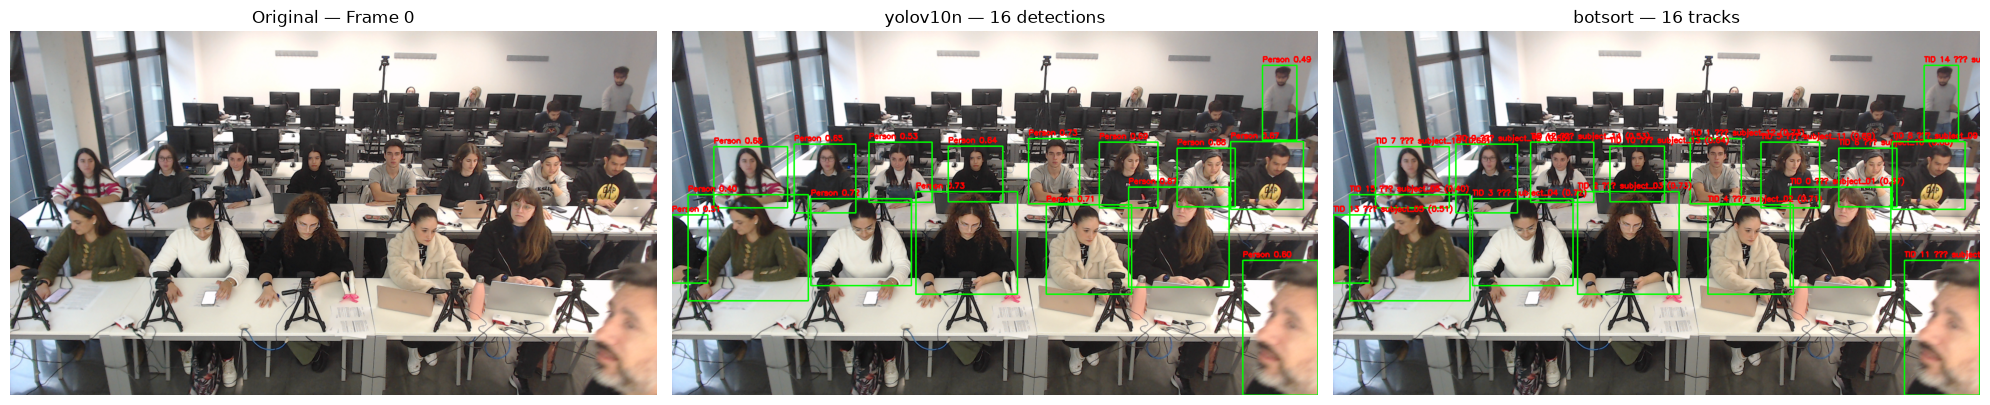

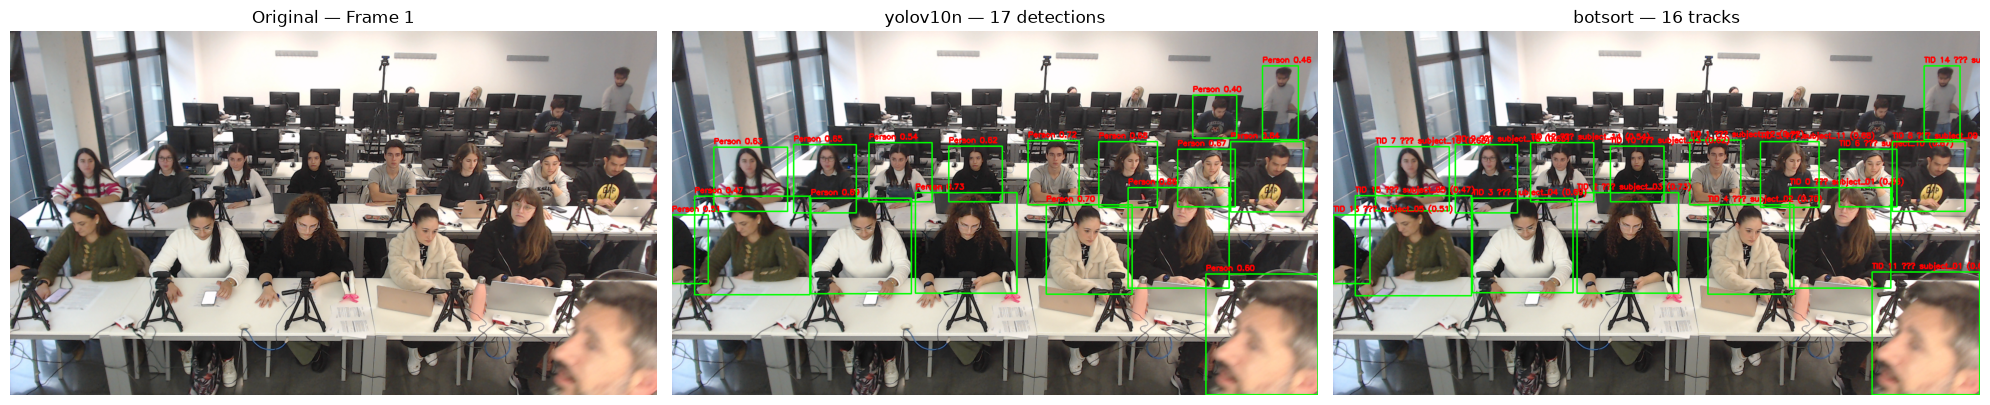

In [ ]:
for item in visualization_frames:
    rgb = item["image"]
    det_labels = [f"Person {s:.2f}" for s in item["det_scores"]]
    track_labels = [
        f"TID {int(t)} → {tid_to_sid.get(int(t), 'unmapped')} ({s:.2f})"
        for t, s in zip(item["track_ids"], item["track_scores"])
    ]

    det_image = draw_boxes(rgb, item["det_boxes"], det_labels)
    track_image = draw_boxes(rgb, item["track_boxes"], track_labels)

    fig, axes = plt.subplots(1, 3, figsize=(20, 7))
    axes[0].imshow(rgb)
    axes[0].set_title(f"Original — Frame {item['index']}")
    axes[1].imshow(det_image)
    axes[1].set_title(f"{DETECTOR_NAME} — {len(det_labels)} detections")
    axes[2].imshow(track_image)
    axes[2].set_title(f"{TRACKER_NAME} — {len(track_labels)} tracks")

    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

## 10. Inspect numerical outputs

The following tables contain the per-frame detection and tracking observations, including the assigned subject ID.

In [281]:
detections_df = pd.DataFrame(detection_records)

print("DETECTOR OUTPUT")
display(detections_df.head(20))

print("TRACKER OUTPUT")
display(tracks_df.head(20))

DETECTOR OUTPUT


,frame_index,timestamp,class_id,confidence,x1,y1,x2,y2
0,0,63333.029516,0,0.872674,904.204773,308.795380,1103.982300,506.925659
1,0,63333.029516,0,0.728206,706.631592,212.898254,807.151062,341.836060
2,0,63333.029516,0,0.726132,483.073853,317.470673,684.033447,520.368958
3,0,63333.029516,0,0.722204,275.273407,331.405731,474.326721,503.560852
4,0,63333.029516,0,0.710966,741.870972,343.210663,910.106812,520.032104
5,0,63333.029516,0,0.692943,846.661499,219.028732,962.234680,349.078735
6,0,63333.029516,0,0.676518,1000.914795,231.483261,1115.553467,347.848328
7,0,63333.029516,0,0.676211,83.761284,228.892456,229.285370,349.100616
8,0,63333.029516,0,0.667679,1106.583496,218.265137,1250.211304,352.453949
9,0,63333.029516,0,0.650992,242.281448,223.854965,364.599823,359.467010


TRACKER OUTPUT


,frame_index,timestamp,track_id,class_id,confidence,x1,y1,x2,y2,subject_id
0,0,63333.029516,0,0,0.872674,904.204712,308.795410,1103.982300,506.925659,subject_01
1,0,63333.029516,1,0,0.728206,706.631592,212.898254,807.151123,341.836060,subject_12
2,0,63333.029516,2,0,0.726132,483.073853,317.470642,684.033447,520.368958,subject_03
3,0,63333.029516,3,0,0.722204,275.273376,331.405701,474.326721,503.560852,subject_04
4,0,63333.029516,4,0,0.710966,741.870972,343.210693,910.106812,520.032104,subject_02
5,0,63333.029516,5,0,0.692943,846.661499,219.028748,962.234741,349.078735,subject_11
6,0,63333.029516,6,0,0.676518,1000.914795,231.483276,1115.553467,347.848328,subject_10
7,0,63333.029516,7,0,0.676211,83.761292,228.892441,229.285370,349.100586,subject_16
8,0,63333.029516,8,0,0.667679,1106.583496,218.265152,1250.211426,352.453979,subject_09
9,0,63333.029516,9,0,0.650992,242.281464,223.854950,364.599823,359.467010,subject_15


### 10.1. Tracking summary

In [282]:
print("Frames processed:", len(frames_to_process))
print("Total detections:", len(detections_df))
print("Total track observations:", len(tracks_df))

if not tracks_df.empty:
    print("Unique track IDs:", tracks_df["track_id"].nunique())
    track_summary = tracks_df.groupby("track_id").agg(
        subject_id=("subject_id", "first"),
        observations=("frame_index", "count"),
        first_frame=("frame_index", "min"),
        last_frame=("frame_index", "max"),
        mean_confidence=("confidence", "mean"),
    ).sort_values("observations", ascending=False)
    display(track_summary)

Frames processed: 60
Total detections: 988
Total track observations: 975
Unique track IDs: 22


,subject_id,observations,first_frame,last_frame,mean_confidence
track_id,,,,,
0,subject_01,60,0,59,0.836937
1,subject_12,60,0,59,0.707018
2,subject_03,60,0,59,0.729062
3,subject_04,60,0,59,0.666741
4,subject_02,60,0,59,0.835741
5,subject_11,60,0,59,0.657159
6,subject_10,60,0,59,0.601906
7,subject_16,60,0,59,0.609732
8,subject_09,60,0,59,0.654173


## 11. Inspect an individual trajectory

Select the most frequently observed track and inspect its bounding boxes across frames.

In [283]:
if not tracks_df.empty:
    selected_tid = track_summary.index[0]
    selected_track = tracks_df[
        tracks_df["track_id"] == selected_tid
    ].sort_values("frame_index")
    print("Selected TID:", selected_tid)
    print("Assigned SID:", tid_to_sid.get(int(selected_tid), "unmapped"))
    display(selected_track)
else:
    print("No tracks were produced.")

Selected TID: 0
Assigned SID: subject_01


,frame_index,timestamp,track_id,class_id,confidence,x1,y1,x2,y2,subject_id
0,0,63333.029516,0,0,0.872674,904.204712,308.795410,1103.982300,506.925659,subject_01
16,1,63333.218115,0,0,0.864525,903.964355,309.473511,1103.746826,508.438232,subject_01
32,2,63333.405856,0,0,0.870929,904.043457,309.407776,1103.711914,509.030426,subject_01
48,3,63333.593239,0,0,0.854244,903.992737,309.374847,1103.662354,508.903564,subject_01
64,4,63333.777172,0,0,0.867865,904.074890,308.312897,1103.494141,509.145782,subject_01
81,5,63335.114339,0,0,0.864288,903.244385,305.481018,1103.610229,507.850494,subject_01
97,6,63335.296331,0,0,0.855087,902.426880,305.884918,1103.528320,506.447571,subject_01
114,7,63335.481812,0,0,0.866842,902.537842,306.202393,1103.535034,506.229248,subject_01
131,8,63335.668609,0,0,0.861535,902.887085,306.144379,1103.472656,505.951019,subject_01
147,9,63335.855175,0,0,0.875176,903.356262,305.682312,1103.255493,505.610962,subject_01


## 12. Cleanup

The temporary extraction directory is no longer needed after inference and visualization.

In [284]:
temp_context.cleanup()
print("Temporary extraction cleaned up.")

Temporary extraction cleaned up.
